# Split and merge: demo de 5 minutos

**TC5056 · Visión computacional**

Implementación didáctica de la familia split and merge. El antecedente principal es Horowitz y Pavlidis (1976), DOI: [10.1145/321941.321956](https://doi.org/10.1145/321941.321956). La implementación usa desviación estándar y una regla propia para seleccionar primer plano; no reproduce literalmente el algoritmo histórico.

La demo contiene tres galaxias reales **de validación**, embebidas para ejecutarse sin el HDF5 de 2.7 GB. El experimento completo ya evaluó **1,000 imágenes por tratamiento**. Estos tres ejemplos explican el algoritmo y sus fallos, y no estiman su desempeño agregado.

En Colab: subir este `.ipynb` mediante **Archivo > Subir notebook**. Ejecutar todas las celdas antes de grabar. La demo usa CPU y no descarga Qwen.

In [ ]:
%pip -q install opencv-python-headless pillow matplotlib pandas

## 1. La función del experimento

Dividimos cada bloque si su desviación estándar excede `tau`, siempre que sus cuatro hijos tengan al menos `min_size` píxeles por lado. Fusionamos regiones vecinas si la desviación de la unión es menor o igual a `tau`. La cola prioriza la menor desviación y usa identificadores para desempatar.

El bloque mínimo puede quedar heterogéneo. Una región homogénea tampoco equivale necesariamente a una galaxia.

In [1]:
"""Segmentación split-and-merge con NumPy y OpenCV.

Los umbrales usan intensidades de 0 a 255. Los valores predeterminados son
puntos de partida que deben ajustarse con imágenes de validación.
"""

import heapq

import cv2
import numpy as np


def segmentar_split_merge(rgb, tau=10.0, min_size=4, fondo_k=3.0):
    """Devuelve (rgb_segmentada, mascara, etiquetas, estadisticas).

    Divide bloques heterogéneos en cuatro y fusiona regiones que comparten
    borde cuando la desviación estándar de su unión es <= tau. La fusión
    prioriza la unión con menor desviación y actualiza las adyacencias.

    La máscara conserva regiones cuya intensidad media supera la mediana
    del borde + fondo_k * sigma robusta del borde. Esta regla supone fondo
    oscuro en el perímetro; no identifica semánticamente la galaxia central.

    Args:
        rgb: Imagen uint8 de forma (alto, ancho, 3), en orden RGB.
        tau: Desviación estándar máxima para considerar homogénea una región.
        min_size: Tamaño mínimo de los hijos al dividir un bloque.
        fondo_k: Distancia al fondo, en unidades de sigma robusta.

    Returns:
        rgb_segmentada: RGB de entrada con fondo negro.
        mascara: uint8, con valores 0 y 255.
        etiquetas: int32, etiquetas consecutivas desde cero, incluido el fondo.
        estadisticas: Conteos y parámetros descriptivos de la segmentación.
    """
    rgb = np.asarray(rgb)
    if (rgb.ndim != 3 or rgb.shape[2] != 3 or rgb.dtype != np.uint8
            or min(rgb.shape[:2]) == 0):
        raise ValueError("rgb debe ser una imagen uint8 no vacía de forma (H, W, 3).")
    if not np.isfinite(tau) or tau < 0:
        raise ValueError("tau debe ser finito y >= 0.")
    if not isinstance(min_size, (int, np.integer)) or min_size < 1:
        raise ValueError("min_size debe ser un entero >= 1.")
    if not np.isfinite(fondo_k) or fondo_k < 0:
        raise ValueError("fondo_k debe ser finito y >= 0.")

    gris = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    alto, ancho = gris.shape
    etiquetas = np.empty((alto, ancho), dtype=np.int32)
    cantidades, sumas, cuadrados = [], [], []

    def dividir(y0, y1, x0, x1):
        bloque = gris[y0:y1, x0:x1].astype(np.float64)
        puede_dividir = (y1 - y0 >= 2 * min_size
                         and x1 - x0 >= 2 * min_size)
        if puede_dividir and bloque.std() > tau:
            ym, xm = (y0 + y1) // 2, (x0 + x1) // 2
            dividir(y0, ym, x0, xm)
            dividir(y0, ym, xm, x1)
            dividir(ym, y1, x0, xm)
            dividir(ym, y1, xm, x1)
        else:
            etiqueta = len(cantidades)
            etiquetas[y0:y1, x0:x1] = etiqueta
            cantidades.append(bloque.size)
            sumas.append(float(bloque.sum()))
            cuadrados.append(float(np.square(bloque).sum()))

    dividir(0, alto, 0, ancho)
    n_split = len(cantidades)
    vecinos = [set() for _ in range(n_split)]

    # Adyacencia de cuatro vecinos, también entre hojas de distinto tamaño.
    for a, b in ((etiquetas[:, :-1], etiquetas[:, 1:]),
                 (etiquetas[:-1, :], etiquetas[1:, :])):
        diferentes = a != b
        pares = np.column_stack((a[diferentes], b[diferentes]))
        pares.sort(axis=1)
        for i, j in np.unique(pares, axis=0):
            vecinos[i].add(int(j))
            vecinos[j].add(int(i))

    padres = np.arange(n_split)
    versiones = np.zeros(n_split, dtype=np.int64)
    pendientes = []

    def desviacion_union(i, j):
        n = cantidades[i] + cantidades[j]
        media = (sumas[i] + sumas[j]) / n
        varianza = (cuadrados[i] + cuadrados[j]) / n - media * media
        return float(np.sqrt(max(0.0, varianza)))

    def proponer(i, j):
        i, j = min(i, j), max(i, j)
        desviacion = desviacion_union(i, j)
        if desviacion <= tau:
            heapq.heappush(pendientes, (desviacion, i, j,
                                       int(versiones[i]), int(versiones[j])))

    for i in range(n_split):
        for j in sorted(vecinos[i]):
            if i < j:
                proponer(i, j)

    while pendientes:
        _, i, j, vi, vj = heapq.heappop(pendientes)
        if (padres[i] != i or padres[j] != j
                or versiones[i] != vi or versiones[j] != vj
                or j not in vecinos[i]):
            continue

        # i absorbe j; las estadísticas permiten calcular la varianza exacta
        # de la unión, sin recorrer otra vez todos sus píxeles.
        padres[j] = i
        cantidades[i] += cantidades[j]
        sumas[i] += sumas[j]
        cuadrados[i] += cuadrados[j]
        versiones[i] += 1
        adyacentes = (vecinos[i] | vecinos[j]) - {i, j}
        for k in sorted(adyacentes):
            vecinos[k].discard(j)
            vecinos[k].add(i)
        vecinos[i] = adyacentes
        vecinos[j].clear()
        for k in sorted(adyacentes):
            proponer(i, k)

    def raiz(i):
        while padres[i] != i:
            padres[i] = padres[padres[i]]
            i = int(padres[i])
        return i

    raices = np.array([raiz(i) for i in range(n_split)])
    regiones, indices = np.unique(raices, return_inverse=True)
    etiquetas = indices[etiquetas].astype(np.int32)
    medias = np.array([sumas[i] / cantidades[i] for i in regiones])

    # Cada píxel del perímetro se cuenta una sola vez, incluso en imágenes
    # de una sola fila o columna.
    borde = np.zeros(gris.shape, dtype=bool)
    borde[[0, -1], :] = True
    borde[:, [0, -1]] = True
    valores_borde = gris[borde].astype(np.float64)
    fondo = float(np.median(valores_borde))
    mad = float(np.median(np.abs(valores_borde - fondo)))
    sigma_fondo = max(1.0, 1.4826 * mad)
    umbral_fondo = fondo + fondo_k * sigma_fondo
    mascara = (medias[etiquetas] > umbral_fondo).astype(np.uint8) * 255
    segmentada = cv2.bitwise_and(rgb, rgb, mask=mascara)
    n_componentes, _ = cv2.connectedComponents(mascara, connectivity=8)

    stats = {
        "otsu_threshold": np.nan,
        "segmented_pct": float(100 * np.count_nonzero(mascara) / mascara.size),
        "num_regions": int(n_componentes - 1),
        "split_regions": n_split,
        "merged_regions": int(len(regiones)),
        "foreground_regions": int(np.count_nonzero(medias > umbral_fondo)),
        "background_threshold": umbral_fondo,
    }
    return segmentada, mascara, etiquetas, stats


In [2]:
import base64, io, json, time
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
CASOS = json.loads("{\"case0\": {\"image_id\": 14633, \"label\": 8, \"prediction\": 8, \"png_b64\": \"...\", \"segmented_pct\": 26.416015625}, \"case1\": {\"image_id\": 8101, \"label\": 5, \"prediction\": 2, \"png_b64\": \"...\", \"segmented_pct\": 1.611328125}, \"case2\": {\"image_id\": 5893, \"label\": 3, \"prediction\": 2, \"png_b64\": \"...\", \"segmented_pct\": 0.0}}")
RESULTADOS = json.loads("[{\"treatment\":\"original\",\"accuracy\":0.282,\"precision_macro\":0.2416648199,\"recall_macro\":0.282,\"f1_macro\":0.2202206498,\"f1_weighted\":0.2202206498,\"invalid_responses\":0,\"invalid_rate\":0.0,\"mean_latency_s\":0.3273583014,\"total_inferences\":1000,\"precision_class_0\":0.0,\"recall_class_0\":0.0,\"f1_class_0\":0.0,\"precision_class_1\":0.701754386,\"recall_class_1\":0.4,\"f1_class_1\":0.5095541401,\"precision_class_2\":0.1908396947,\"recall_class_2\":1.0,\"f1_class_2\":0.3205128205,\"precision_class_3\":0.0,\"recall_class_3\":0.0,\"f1_class_3\":0.0,\"precision_class_4\":0.275862069,\"recall_class_4\":0.32,\"f1_class_4\":0.2962962963,\"precision_class_5\":0.3103448276,\"recall_class_5\":0.27,\"f1_class_5\":0.2887700535,\"precision_class_6\":0.0,\"recall_class_6\":0.0,\"f1_class_6\":0.0,\"precision_class_7\":0.2222222222,\"recall_class_7\":0.02,\"f1_class_7\":0.0366972477,\"precision_class_8\":0.515625,\"recall_class_8\":0.66,\"f1_class_8\":0.5789473684,\"precision_class_9\":0.2,\"recall_class_9\":0.15,\"f1_class_9\":0.1714285714,\"mean_otsu_threshold\":\"\",\"mean_segmented_pct\":\"\",\"mean_num_regions\":\"\",\"mean_split_regions\":\"\",\"mean_merged_regions\":\"\",\"mean_foreground_regions\":\"\",\"mean_background_threshold\":\"\",\"mean_preprocessing_s\":\"\",\"empty_masks\":\"\",\"full_masks\":\"\"},{\"treatment\":\"gaussian\",\"accuracy\":0.286,\"precision_macro\":0.2857003083,\"recall_macro\":0.286,\"f1_macro\":0.2224317597,\"f1_weighted\":0.2224317597,\"invalid_responses\":0,\"invalid_rate\":0.0,\"mean_latency_s\":0.325664789,\"total_inferences\":1000,\"precision_class_0\":0.0,\"recall_class_0\":0.0,\"f1_class_0\":0.0,\"precision_class_1\":0.8222222222,\"recall_class_1\":0.37,\"f1_class_1\":0.5103448276,\"precision_class_2\":0.2016129032,\"recall_class_2\":1.0,\"f1_class_2\":0.3355704698,\"precision_class_3\":0.0,\"recall_class_3\":0.0,\"f1_class_3\":0.0,\"precision_class_4\":0.2385321101,\"recall_class_4\":0.26,\"f1_class_4\":0.2488038278,\"precision_class_5\":0.3366336634,\"recall_class_5\":0.34,\"f1_class_5\":0.3383084577,\"precision_class_6\":0.2222222222,\"recall_class_6\":0.02,\"f1_class_6\":0.0366972477,\"precision_class_7\":0.4,\"recall_class_7\":0.02,\"f1_class_7\":0.0380952381,\"precision_class_8\":0.4671052632,\"recall_class_8\":0.71,\"f1_class_8\":0.5634920635,\"precision_class_9\":0.1686746988,\"recall_class_9\":0.14,\"f1_class_9\":0.1530054645,\"mean_otsu_threshold\":\"\",\"mean_segmented_pct\":\"\",\"mean_num_regions\":\"\",\"mean_split_regions\":\"\",\"mean_merged_regions\":\"\",\"mean_foreground_regions\":\"\",\"mean_background_threshold\":\"\",\"mean_preprocessing_s\":\"\",\"empty_masks\":\"\",\"full_masks\":\"\"},{\"treatment\":\"clahe\",\"accuracy\":0.31,\"precision_macro\":0.2515393042,\"recall_macro\":0.31,\"f1_macro\":0.2386808058,\"f1_weighted\":0.2386808058,\"invalid_responses\":0,\"invalid_rate\":0.0,\"mean_latency_s\":0.2960986306,\"total_inferences\":1000,\"precision_class_0\":0.0,\"recall_class_0\":0.0,\"f1_class_0\":0.0,\"precision_class_1\":0.6593406593,\"recall_class_1\":0.6,\"f1_class_1\":0.6282722513,\"precision_class_2\":0.2403846154,\"recall_class_2\":1.0,\"f1_class_2\":0.3875968992,\"precision_class_3\":0.0,\"recall_class_3\":0.0,\"f1_class_3\":0.0,\"precision_class_4\":0.2644628099,\"recall_class_4\":0.32,\"f1_class_4\":0.2895927602,\"precision_class_5\":0.2941176471,\"recall_class_5\":0.3,\"f1_class_5\":0.297029703,\"precision_class_6\":0.1428571429,\"recall_class_6\":0.01,\"f1_class_6\":0.0186915888,\"precision_class_7\":0.3333333333,\"recall_class_7\":0.06,\"f1_class_7\":0.1016949153,\"precision_class_8\":0.4223602484,\"recall_class_8\":0.68,\"f1_class_8\":0.5210727969,\"precision_class_9\":0.1585365854,\"recall_class_9\":0.13,\"f1_class_9\":0.1428571429,\"mean_otsu_threshold\":\"\",\"mean_segmented_pct\":\"\",\"mean_num_regions\":\"\",\"mean_split_regions\":\"\",\"mean_merged_regions\":\"\",\"mean_foreground_regions\":\"\",\"mean_background_threshold\":\"\",\"mean_preprocessing_s\":\"\",\"empty_masks\":\"\",\"full_masks\":\"\"},{\"treatment\":\"gaussian_otsu\",\"accuracy\":0.23,\"precision_macro\":0.2288004079,\"recall_macro\":0.23,\"f1_macro\":0.1698002788,\"f1_weighted\":0.1698002788,\"invalid_responses\":0,\"invalid_rate\":0.0,\"mean_latency_s\":0.3090039629,\"total_inferences\":1000,\"precision_class_0\":0.1111111111,\"recall_class_0\":0.01,\"f1_class_0\":0.0183486239,\"precision_class_1\":0.6538461538,\"recall_class_1\":0.34,\"f1_class_1\":0.4473684211,\"precision_class_2\":0.199195171,\"recall_class_2\":0.99,\"f1_class_2\":0.3316582915,\"precision_class_3\":0.0,\"recall_class_3\":0.0,\"f1_class_3\":0.0,\"precision_class_4\":0.1901140684,\"recall_class_4\":0.5,\"f1_class_4\":0.2754820937,\"precision_class_5\":0.3050847458,\"recall_class_5\":0.18,\"f1_class_5\":0.2264150943,\"precision_class_6\":0.0,\"recall_class_6\":0.0,\"f1_class_6\":0.0,\"precision_class_7\":0.0,\"recall_class_7\":0.0,\"f1_class_7\":0.0,\"precision_class_8\":0.7407407407,\"recall_class_8\":0.2,\"f1_class_8\":0.3149606299,\"precision_class_9\":0.0879120879,\"recall_class_9\":0.08,\"f1_class_9\":0.0837696335,\"mean_otsu_threshold\":86.321,\"mean_segmented_pct\":5.4582077026,\"mean_num_regions\":9.236,\"mean_split_regions\":\"\",\"mean_merged_regions\":\"\",\"mean_foreground_regions\":\"\",\"mean_background_threshold\":\"\",\"mean_preprocessing_s\":\"\",\"empty_masks\":\"\",\"full_masks\":\"\"},{\"treatment\":\"clahe_otsu\",\"accuracy\":0.313,\"precision_macro\":0.3439132316,\"recall_macro\":0.313,\"f1_macro\":0.24717084,\"f1_weighted\":0.24717084,\"invalid_responses\":0,\"invalid_rate\":0.0,\"mean_latency_s\":0.3079922346,\"total_inferences\":1000,\"precision_class_0\":0.6666666667,\"recall_class_0\":0.02,\"f1_class_0\":0.0388349515,\"precision_class_1\":0.6161616162,\"recall_class_1\":0.61,\"f1_class_1\":0.6130653266,\"precision_class_2\":0.2414634146,\"recall_class_2\":0.99,\"f1_class_2\":0.3882352941,\"precision_class_3\":0.0,\"recall_class_3\":0.0,\"f1_class_3\":0.0,\"precision_class_4\":0.2538461538,\"recall_class_4\":0.33,\"f1_class_4\":0.2869565217,\"precision_class_5\":0.3157894737,\"recall_class_5\":0.3,\"f1_class_5\":0.3076923077,\"precision_class_6\":0.1666666667,\"recall_class_6\":0.01,\"f1_class_6\":0.0188679245,\"precision_class_7\":0.5882352941,\"recall_class_7\":0.1,\"f1_class_7\":0.1709401709,\"precision_class_8\":0.3636363636,\"recall_class_8\":0.6,\"f1_class_8\":0.4528301887,\"precision_class_9\":0.2266666667,\"recall_class_9\":0.17,\"f1_class_9\":0.1942857143,\"mean_otsu_threshold\":84.996,\"mean_segmented_pct\":33.5811233521,\"mean_num_regions\":2000.642,\"mean_split_regions\":\"\",\"mean_merged_regions\":\"\",\"mean_foreground_regions\":\"\",\"mean_background_threshold\":\"\",\"mean_preprocessing_s\":\"\",\"empty_masks\":\"\",\"full_masks\":\"\"},{\"treatment\":\"gaussian_split_merge\",\"accuracy\":0.218,\"precision_macro\":0.2020441029,\"recall_macro\":0.218,\"f1_macro\":0.1564738429,\"f1_weighted\":0.1564738429,\"invalid_responses\":0,\"invalid_rate\":0.0,\"mean_latency_s\":0.296268133,\"total_inferences\":1000,\"precision_class_0\":0.1176470588,\"recall_class_0\":0.04,\"f1_class_0\":0.0597014925,\"precision_class_1\":0.7272727273,\"recall_class_1\":0.24,\"f1_class_1\":0.3609022556,\"precision_class_2\":0.2150776053,\"recall_class_2\":0.97,\"f1_class_2\":0.3520871143,\"precision_class_3\":0.0,\"recall_class_3\":0.0,\"f1_class_3\":0.0,\"precision_class_4\":0.1489361702,\"recall_class_4\":0.21,\"f1_class_4\":0.1742738589,\"precision_class_5\":0.1927710843,\"recall_class_5\":0.48,\"f1_class_5\":0.2750716332,\"precision_class_6\":0.0,\"recall_class_6\":0.0,\"f1_class_6\":0.0,\"precision_class_7\":0.0,\"recall_class_7\":0.0,\"f1_class_7\":0.0,\"precision_class_8\":0.4705882353,\"recall_class_8\":0.16,\"f1_class_8\":0.2388059701,\"precision_class_9\":0.1481481481,\"recall_class_9\":0.08,\"f1_class_9\":0.1038961039,\"mean_otsu_threshold\":\"\",\"mean_segmented_pct\":7.9231445313,\"mean_num_regions\":3.633,\"mean_split_regions\":355.378,\"mean_merged_regions\":72.105,\"mean_foreground_regions\":70.797,\"mean_background_threshold\":48.9704398,\"mean_preprocessing_s\":0.0249830512,\"empty_masks\":5.0,\"full_masks\":1.0},{\"treatment\":\"clahe_split_merge\",\"accuracy\":0.162,\"precision_macro\":0.1595355864,\"recall_macro\":0.162,\"f1_macro\":0.0925978059,\"f1_weighted\":0.0925978059,\"invalid_responses\":0,\"invalid_rate\":0.0,\"mean_latency_s\":0.3002403779,\"total_inferences\":1000,\"precision_class_0\":0.0694444444,\"recall_class_0\":0.05,\"f1_class_0\":0.0581395349,\"precision_class_1\":0.2857142857,\"recall_class_1\":0.02,\"f1_class_1\":0.0373831776,\"precision_class_2\":0.1655629139,\"recall_class_2\":1.0,\"f1_class_2\":0.2840909091,\"precision_class_3\":0.0,\"recall_class_3\":0.0,\"f1_class_3\":0.0,\"precision_class_4\":0.1592356688,\"recall_class_4\":0.25,\"f1_class_4\":0.1945525292,\"precision_class_5\":0.1826086957,\"recall_class_5\":0.21,\"f1_class_5\":0.1953488372,\"precision_class_6\":0.0,\"recall_class_6\":0.0,\"f1_class_6\":0.0,\"precision_class_7\":0.3333333333,\"recall_class_7\":0.02,\"f1_class_7\":0.0377358491,\"precision_class_8\":0.3125,\"recall_class_8\":0.05,\"f1_class_8\":0.0862068966,\"precision_class_9\":0.0869565217,\"recall_class_9\":0.02,\"f1_class_9\":0.0325203252,\"mean_otsu_threshold\":\"\",\"mean_segmented_pct\":2.9447998047,\"mean_num_regions\":6.526,\"mean_split_regions\":4060.285,\"mean_merged_regions\":3970.012,\"mean_foreground_regions\":60.885,\"mean_background_threshold\":164.0543644,\"mean_preprocessing_s\":0.0695281575,\"empty_masks\":0.0,\"full_masks\":0.0}]")


## 2. Tres ejemplos seleccionados para explicar el comportamiento

1. Galaxia de perfil con clasificación correcta en Gaussian + split and merge.
2. Espiral barrada de clase 5, ID 8101, para revisar la conservación de estructuras tenues.
3. Primera galaxia, por identificador, que produjo máscara vacía en ese tratamiento.

Son ejemplos escogidos para mostrar contrastes, no una muestra aleatoria ni máscaras de referencia.

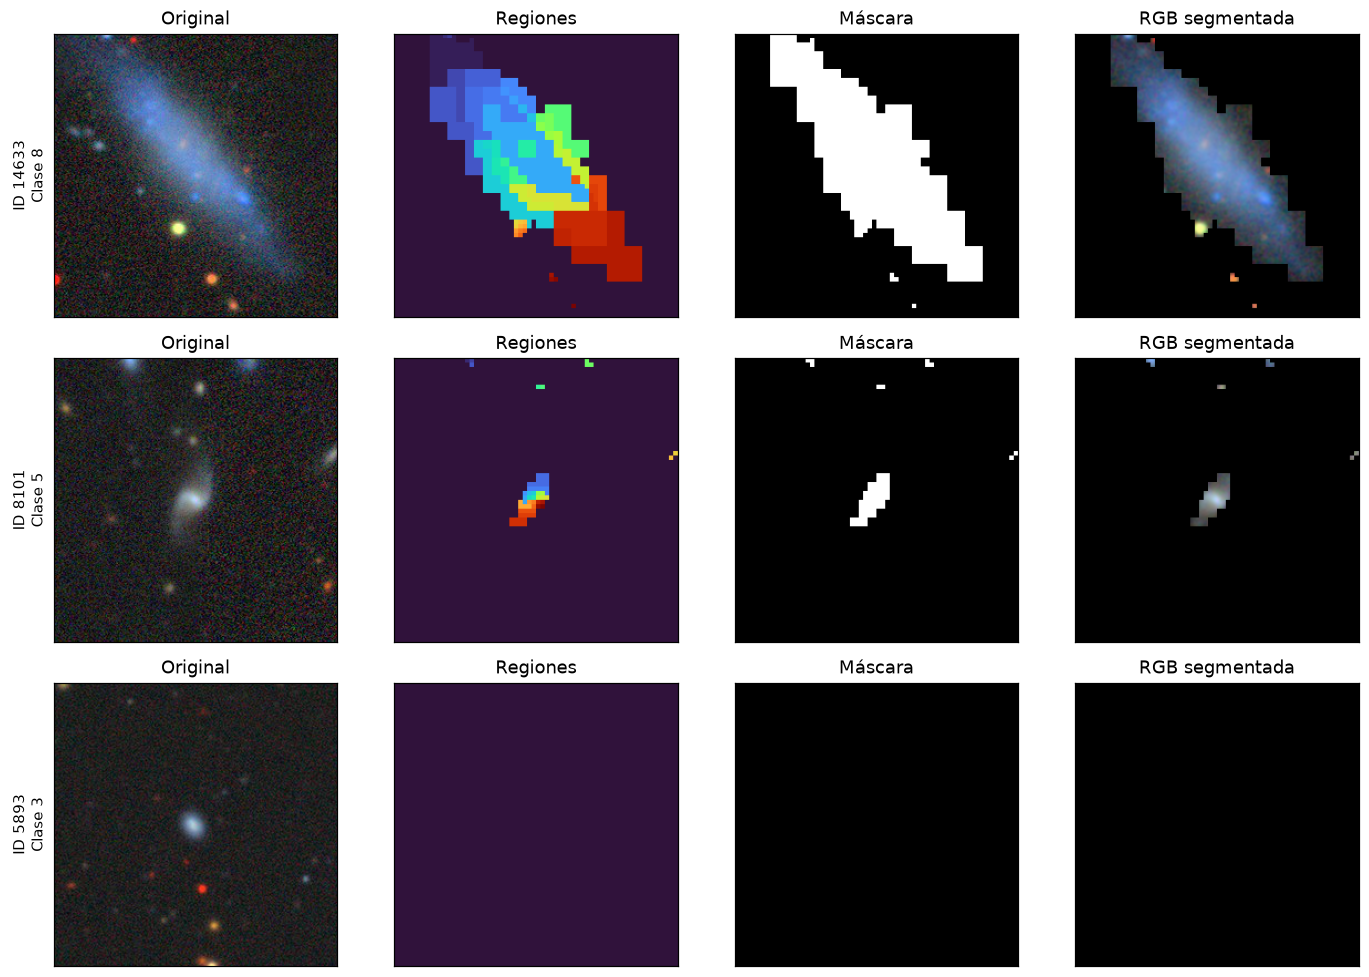

,image_id,clase_real,prediccion_Qwen_guardada,pct_conservado,regiones_split,regiones_merge,tiempo_demo_s
0,14633,8,8,26.416016,394,54,0.028955
1,8101,5,2,1.611328,262,33,0.020615
2,5893,3,2,0.000000,1,1,0.001178


In [3]:
registros = []
fig, axes = plt.subplots(len(CASOS), 4, figsize=(13, 9), squeeze=False)
for i, (nombre, caso) in enumerate(CASOS.items()):
    rgb = np.array(Image.open(io.BytesIO(base64.b64decode(caso['png_b64']))).convert('RGB'))
    procesada = cv2.GaussianBlur(rgb, (5, 5), sigmaX=1)
    inicio = time.perf_counter()
    segmentada, mascara, etiquetas, stats = segmentar_split_merge(procesada, tau=10, min_size=4, fondo_k=3)
    duracion = time.perf_counter() - inicio
    for ax, imagen, titulo in zip(axes[i], [rgb, etiquetas, mascara, segmentada],
                                  ['Original', 'Regiones', 'Máscara', 'RGB segmentada']):
        ax.imshow(imagen, cmap='turbo' if titulo == 'Regiones' else 'gray')
        ax.set_title(titulo)
        ax.set_xticks([]); ax.set_yticks([])
    axes[i, 0].set_ylabel(f"ID {caso['image_id']}\nClase {caso['label']}")
    assert abs(stats['segmented_pct'] - caso['segmented_pct']) < 1e-9
    registros.append({'image_id': caso['image_id'], 'clase_real': caso['label'],
        'prediccion_Qwen_guardada': caso['prediction'], 'pct_conservado': stats['segmented_pct'],
        'regiones_split': stats['split_regions'], 'regiones_merge': stats['merged_regions'],
        'tiempo_demo_s': duracion})
plt.tight_layout()
plt.show()
pd.DataFrame(registros)


## 3. Resultados completos del experimento

Las predicciones de Qwen son resultados previamente calculados. Esta demo vuelve a ejecutar la segmentación, pero **no ejecuta las 7,000 inferencias**. Se mantuvieron modelo, prompt, imágenes y generación determinista. Las 2,000 imágenes de prueba permanecieron reservadas.

Accuracy y F1 macro evalúan **clasificación morfológica**. El porcentaje conservado y el número de regiones describen la máscara. No contamos con máscaras de referencia para calcular IoU o Dice.

,treatment,total_inferences,accuracy,f1_macro
4,clahe_otsu,1000,0.313,0.247171
2,clahe,1000,0.310,0.238681
1,gaussian,1000,0.286,0.222432
0,original,1000,0.282,0.220221
3,gaussian_otsu,1000,0.230,0.169800
5,gaussian_split_merge,1000,0.218,0.156474
6,clahe_split_merge,1000,0.162,0.092598


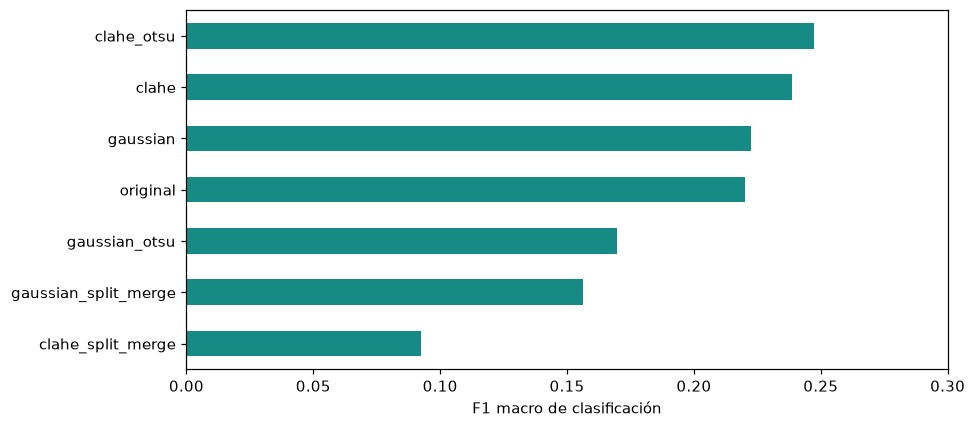

In [4]:
tabla = pd.DataFrame(RESULTADOS)
display(tabla[['treatment', 'total_inferences', 'accuracy', 'f1_macro']].sort_values('f1_macro', ascending=False))
ax = tabla.sort_values('f1_macro').plot.barh(x='treatment', y='f1_macro', legend=False,
    figsize=(9, 4), color='#168b85', xlim=(0, .30))
ax.set_xlabel('F1 macro de clasificación')
ax.set_ylabel('')
plt.tight_layout()
plt.show()


## 4. Interpretación y fuentes

Con estos parámetros, split and merge redujo el desempeño de Qwen. El recorte de estructuras tenues es una hipótesis visual, no una causa demostrada. La evaluación mezcla el particionado de regiones y nuestra regla de primer plano. Cambiar parámetros requiere registrar una nueva configuración y conservar la prueba final intacta.

- Horowitz, S. L., & Pavlidis, T. (1976). *Picture Segmentation by a Tree Traversal Algorithm*. Journal of the ACM, 23(2), 368-388. https://doi.org/10.1145/321941.321956
- Fu, G., Zhao, H., Li, C., & Shi, L. (2013). *Segmentation for High-Resolution Optical Remote Sensing Imagery Using Improved Quadtree and Region Adjacency Graph Technique*. Remote Sensing, 5(7), 3259-3279. https://doi.org/10.3390/rs5073259
- Otsu, N. (1979). *A Threshold Selection Method from Gray-Level Histograms*. IEEE Transactions on Systems, Man, and Cybernetics, 9(1), 62-66. https://doi.org/10.1109/TSMC.1979.4310076
- Leung, W. H., & Bovy, J. (2024). *Galaxy10 DECaLS* [Dataset]. Zenodo. https://doi.org/10.5281/zenodo.10845026
- OpenCV. *Image Thresholding*. https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html

Evidencia local: `resultados_qwen/*/metrics.json`, `predictions.csv`, `config.json`, y `comparacion_mlflow.csv`. La función incluida coincide con `segmentacion.py` del experimento.